## Load Packages, Silently

In [44]:
## Create a vector of the required packages for this analysis
req_packages <- c("ape", "Biostrings", "BSgenome",  "clevr", "cowplot", "GenomicFeatures", "ggplot2", "ggpubr", "ggtree",
                  "gridExtra", "janitor", "nlme", "patchwork", "RColorBrewer", "stringr", 
                  "tidyverse", "treeio", "TreeTools", "txdbmaker", "vegan")

## load the packages, quietly
invisible(suppressWarnings(suppressMessages(
    lapply(req_packages, require, character.only = TRUE)
)))

## Identify variants in D. pseudoobscura mutant

### Set up Data

In [45]:
## load in vep results
raw_variants <- read_tsv("../workflow/tools/VEP/variant_effect_output.txt", skip = 95) %>%
    janitor::clean_names()

## clean up the column information
all_variants <- raw_variants %>%
    separate_wider_delim(extra, ";", names = c("impact", "distance", "strand", "class", "symbol", "biotype"), 
                         too_few = "align_start", too_many = "drop") %>%
    mutate(biotype = case_when(grepl("BIOTYPE", symbol) ~ symbol,
                               TRUE ~ biotype),
           symbol = case_when(grepl("SYMBOL", class) ~ class,
                              TRUE ~ symbol),
           class = case_when(grepl("VARIANT_CLASS", distance) ~ distance,
                             grepl("VARIANT_CLASS", strand) ~ strand,
                             TRUE ~ class),
           strand = case_when(grepl("STRAND", distance) ~ distance,
                              TRUE ~ strand),
           distance = case_when(!grepl("DISTANCE", distance) ~ NA,
                                TRUE ~ distance)) %>%
    mutate(across(everything(), ~ str_replace(., ".*=", ""))) %>%
    separate_wider_delim(number_uploaded_variation, "_", names = c("chromosome", "position", "change"), too_few = "align_start", too_many = "drop") %>%
    mutate(position = as.integer(position))

## filter for only variants on the XR
variants <- all_variants %>%
    filter(grepl("ChrX", chromosome)) %>%
    filter(grepl("ChrX.1", chromosome) | grepl("ChrX.4", chromosome))

## visualize clean data
head(variants)

Warning message:
“One or more parsing issues, call `problems()` on your data frame for details,
e.g.:
  dat <- vroom(...)
  problems(dat)”
Rows: 5891958 Columns: 14
── Column specification ────────────────────────────────────────────────────────
Delimiter: "\t"
chr (14): #Uploaded_variation, Location, Allele, Gene, Feature, Feature_type...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


chromosome,position,change,location,allele,gene,feature,feature_type,consequence,c_dna_position,⋯,protein_position,amino_acids,codons,existing_variation,impact,distance,strand,class,symbol,biotype
<chr>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,⋯,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
ChrX.1,1173,G/A,ChrX.1:1173,A,-,-,-,intergenic_variant,-,⋯,-,-,-,-,MODIFIER,NA,NA,SNV,NA,NA
ChrX.1,8650,A/T,ChrX.1:8650,T,-,-,-,intergenic_variant,-,⋯,-,-,-,-,MODIFIER,NA,NA,SNV,NA,NA
ChrX.1,9376,T/C,ChrX.1:9376,C,-,-,-,intergenic_variant,-,⋯,-,-,-,-,MODIFIER,NA,NA,SNV,NA,NA
ChrX.1,9421,-/T,ChrX.1:9420-9421,T,-,-,-,intergenic_variant,-,⋯,-,-,-,-,MODIFIER,NA,NA,insertion,NA,NA
ChrX.1,9423,A/C,ChrX.1:9423,C,-,-,-,intergenic_variant,-,⋯,-,-,-,-,MODIFIER,NA,NA,SNV,NA,NA
ChrX.1,9441,T/C,ChrX.1:9441,C,-,-,-,intergenic_variant,-,⋯,-,-,-,-,MODIFIER,NA,NA,SNV,NA,NA


In [46]:
## load in SFP data from Garlovsky et al. 2022
sperm_sfp <- read_csv("input/sperm_sfp_garlovsky(2022).csv")
sfp <- read_csv("input/refined_sfp_garlovsky(2022).csv")

## load in orthologs between D. melanogaster and D. pseudoobscura
mel_ortho <- read_delim("../workflow/trinotate/drosoma_pse_mel.txt", col_names = FALSE)
names(mel_ortho) <- c("dpse", "dmel", "paralog", "score")

## load in tau data
tau <- read.csv("../workflow/yang2018_rnaseq/results/tau_tissue_0.50.csv")
testes_genes <- tau %>%
    filter(tau_tissue == "male_gonad") %>%
    pull("gene")

Rows: 7 Columns: 4
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (2): FBgn, NAME
dbl (2): Accessory glands, Testis

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


Rows: 68 Columns: 4
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (3): FBgn, Symbol, Chromosome
dbl (1): Abundance

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 13772 Columns: 4
── Column specification ────────────────────────────────────────────────────────
Delimiter: "\t"
chr (3): X1, X2, X3
dbl (1): X4

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


### Check the summary information for variant effect

In [47]:
## count how many variants
nrow(variants)

[1] 306663

In [48]:
## count the number of SNPs
variants %>%
    filter(class == "SNV") %>%
    nrow()

[1] 240546

In [49]:
## count the number of genes with mutations
variants %>%
    pull("symbol") %>%
    na.omit() %>%
    unique() %>%
    length()

[1] 731

In [50]:
## annotate mutation types
variant_type <- variants %>%
    separate_longer_delim(consequence, delim = ",") %>%
    mutate(type = case_when(grepl("UTR", consequence) ~ "UTR",
                            grepl("splice", consequence) ~ "splicing",
                            grepl("intron", consequence) ~ "intron",
                            grepl("frameshift", consequence) ~ "frameshift",
                            grepl("inframe", consequence) ~ "inframe",
                            grepl("start_lost", consequence) | grepl("stop_gained", consequence) ~ "nonsense",
                            grepl("missense", consequence) ~ "missense",
                            grepl("protein_altering", consequence) ~ "protein altering",
                            grepl("stream_gene_variant", consequence) ~ "distal"))

## count how many variants of each type
variant_type_number <- variant_type %>%
    select(type, symbol) %>%
    na.omit() %>%
    unique() %>%
    count(type)
variant_type_number

type,n
<chr>,<int>
UTR,545
distal,730
frameshift,42
inframe,135
intron,487
missense,369
nonsense,8
protein altering,4
splicing,303


In [51]:
## define regulatory sequences
regulator <- c("upstream_gene_variant", "downstream_gene_variant", "3_prime_UTR_variant", "5_prime_UTR_variant")

## count the number of mutations per gene
multi_mutations <- variants %>%
    separate_longer_delim(consequence, ",") %>%
    filter(biotype == "protein_coding" & consequence != "synonymous_variant") %>%
    mutate(mutation_type = case_when(consequence %in% regulator ~ "Regulatory Element",
                             consequence == "intron_variant" ~ "Intron Variant",
                             grepl("splice", consequence) ~ "Splicing Variant",
                             grepl("inframe", consequence) ~ "Inframe InDel",
                             grepl("frameshift", consequence) ~ "Frameshift InDel",
                             consequence == "protein_altering_variant" ~ "Protein Altering",
                             consequence == "stop_gained" ~ "Nonsense Mutation",
                             consequence == "start_lost" ~ "Start Lost",
                             TRUE ~ "Other")) %>%
    group_by(mutation_type, symbol) %>%
    reframe(count = n())
head(multi_mutations)

mutation_type,symbol,count
<chr>,<chr>,<int>
Frameshift InDel,LOC117184369,2
Frameshift InDel,LOC26532021,1
Frameshift InDel,LOC26532600,1
Frameshift InDel,LOC4805581,2
Frameshift InDel,LOC4805583,4
Frameshift InDel,LOC4805584,8


In [52]:
## calculate the limit that 99% of genes are within
cap <- quantile(multi_mutations$count, probs = 0.75)
attributes(cap) <- NULL
cap

[1] 118

In [53]:
## find the highest number of mutations in a single gene
max(multi_mutations$count)

[1] 9615

In [54]:
## find the median number of mutations per gene
median(multi_mutations$count)

[1] 13

### Identify potential mutations of interest

In [55]:
## identify protein altering and nonsense mutations
potential_interest <- variants %>%
    filter(consequence == "protein_altering_variant" | consequence == "stop_gained") %>%
    select(symbol, position, change, consequence) %>%
    unique()
potential_interest

symbol,position,change,consequence
<chr>,<int>,<chr>,<chr>
LOC6901779,645002,-/AGCCAC,protein_altering_variant
LOC4815337,893839,G/C,stop_gained
LOC6902117,1625489,-/TGT,protein_altering_variant
LOC4815785,2706647,G/T,stop_gained
LOC4815774,2949241,C/T,stop_gained
LOC4815426,3468139,-/ACCAGT,protein_altering_variant
LOC6902257,4221843,-/TGCTGC,protein_altering_variant
LOC4815659,4250261,C/A,stop_gained
LOC26532021,4393675,T/G,stop_gained


### Determine if mutations of interest are testis specific and/or sperm proteins

In [56]:
## correct symbol name to shorter name
sperm_sfp$dmel <- c("Idgf3", "Tsf1", "Idgf4", "CG6357", "scpr-C", "NT5E-2", "Pde1c")

## identify the D. pseudoobscura orthologs
sperm_dpse <- sperm_sfp %>%
    inner_join(mel_ortho, by = "dmel") %>%
    select(dpse, NAME) %>%
    rename(sperm_protein = NAME, symbol = dpse)

## correctsymbol name to short name
sfp_x <- sfp %>%
    filter(Chromosome == "X")
sfp_x$dmel <- c("regucalcin", "Tsf1", "CG5162", "Hsc70-3", "Idgf4", "CG18258", "Grp170")

## identify the D. pseudoobscura orthologs
sfp_dpse <- sfp_x %>%
    inner_join(mel_ortho, by = "dmel") %>%
    select(dpse, Symbol) %>%
    rename(sfp = Symbol, symbol = dpse)

## identify expression of genes
tissue_expression <- tau %>%
    select(gene, max_organ, tau_tissue) %>%
    rename(symbol = gene)

In [57]:
## add sperm information to mutation of interest data frame
potential_annotated <- potential_interest %>%
    left_join(sperm_dpse, by = "symbol") %>%
    left_join(sfp_dpse, by = "symbol") %>%
    left_join(tissue_expression, by = "symbol")

potential_annotated

symbol,position,change,consequence,sperm_protein,sfp,max_organ,tau_tissue
<chr>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
LOC6901779,645002,-/AGCCAC,protein_altering_variant,NA,NA,female_abdomen,ambiguous
LOC4815337,893839,G/C,stop_gained,NA,NA,female_gonad,ambiguous
LOC6902117,1625489,-/TGT,protein_altering_variant,NA,NA,female_gonad,ambiguous
LOC4815785,2706647,G/T,stop_gained,NA,NA,male_head,ambiguous
LOC4815774,2949241,C/T,stop_gained,NA,NA,male_digestive,ambiguous
LOC4815426,3468139,-/ACCAGT,protein_altering_variant,NA,NA,female_abdomen,ambiguous
LOC6902257,4221843,-/TGCTGC,protein_altering_variant,NA,NA,male_gonad,ambiguous
LOC4815659,4250261,C/A,stop_gained,NA,NA,female_thorax,ambiguous
LOC26532021,4393675,T/G,stop_gained,NA,NA,male_head,male_head


## Characterize gene expression in D. pseudoobscura mutant

### Set up Data

In [58]:
## load in LogFC data
comparison_norm <- read_csv("../workflow/multigenome_rnaseq/results/logfc_normalized.csv")
head(comparison_norm)

New names:
• `` -> `...1`
Rows: 28593 Columns: 8
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (5): gene, comparison, significance, direction, color
dbl (3): ...1, logfc, pvalue

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


...1,gene,comparison,logfc,pvalue,significance,direction,color
<dbl>,<chr>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>
1,HCS66_mgp12,sex ratio_reference,-0.7478660,3.116607e-08,significant,hypo,marginally differentially expressed
2,HCS66_mgp12,sex ratio_mutant,-0.6487602,6.394837e-08,significant,hypo,marginally differentially expressed
3,HCS66_mgp12,reference_mutant,0.1097625,9.912583e-01,not significant,hyper,not significant
4,HCS66_mgp11,sex ratio_reference,-1.4785039,1.809080e-08,significant,hypo,marginally differentially expressed
5,HCS66_mgp11,sex ratio_mutant,-0.9880289,7.678211e-07,significant,hypo,marginally differentially expressed
6,HCS66_mgp11,reference_mutant,0.5010003,1.917109e-03,significant,hyper,marginally differentially expressed


In [59]:
## load in results of Trinotate
ontology <- read_csv("../workflow/trinotate/dpse_goterms.csv") %>%
    select(-1)
head(ontology)

New names:
• `` -> `...1`
Rows: 915220 Columns: 4
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (3): gene, term, category
dbl (1): ...1

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


gene,term,category
<chr>,<chr>,<chr>
HCS66_mgp01,catalytic activity,molecular_function
HCS66_mgp01,cytochrome-c oxidase activity,molecular_function
HCS66_mgp01,transporter activity,molecular_function
HCS66_mgp01,binding,molecular_function
HCS66_mgp01,copper ion binding,molecular_function
HCS66_mgp01,cellular_component,molecular_function


In [60]:
### create database for genes from GFF
dpse_ranges <- makeTxDbFromGFF("/home/yahmed-labshare/data/genomes/obscura_group/pseudoobscura/GCF_009870125.1/genomic.gff", format = "gff")

### load in fasta of pseudoobscura
dpse_fasta <- readDNAStringSet("/home/yahmed-labshare/data/genomes/obscura_group/pseudoobscura/GCF_009870125.1/GCF_009870125.1_UCI_Dpse_MV25_genomic.fna")

Import genomic features from the file as a GRanges object ... 


OK

Prepare the 'metadata' data frame ... 
OK

Make the TxDb object ... 
Warning message in .extract_transcripts_from_GRanges(tx_IDX, gr, mcols0$type, mcols0$ID, :
“some transcripts have no "transcript_id" attribute ==> their name
  ("tx_name" column in the TxDb object) was set to NA”
Warning message in .extract_transcripts_from_GRanges(tx_IDX, gr, mcols0$type, mcols0$ID, :
“the transcript names ("tx_name" column in the TxDb object) imported
  from the "transcript_id" attribute are not unique”
OK



### Correlate Sperm Length with Parasperm Production

In [61]:
## load in tree
full_obscura_tree <- ape::read.tree("input/obscura_tree.nwk")

In [62]:
## save data from Holman et al. 2007
species <- c("affinis", "athabasca", "azteca", "tolteca", "persimilis", "pseudoobscura", "miranda", "ambigua", "obscura", "imaii", "subobscura")
drosophila_species <- paste0("Drosophila_", species)
percent_parasperm <- c(72, 94, 88, 69, 50, 50, 56, 73, 34, 42, 66)

eusperm_length <- c(506, 1527, 1433, 303, 324, 362, 309, 313, 230, 208, 408)
eusperm_head <- c(91, 449, 351, 56, 70, 70, 61, 59, 51, 65, 72)
eusperm_tail <- c(414, 1088, 1097, 247, 254, 293, 248, 253, 180, 143, 334)

parasperm_length <- c(130, 118, 174, 98, 77, 92, 87, 94, 96, 69, 227)
parasperm_head <- c(20, 15, 15, 15, 13, 14, 13, 16, 23, 19, 26)
parasperm_tail <- c(110, 102, 159, 83, 64, 78, 74, 74, 73, 50, 200)

mrt_mass <- c(11, 13, 17, 15, 26, 22, 41, 24, 28, 20, 10)

## create dataframe
traits <- data.frame(species = drosophila_species, percent_parasperm = percent_parasperm,
                     eusperm_length = eusperm_length, eusperm_head = eusperm_head, eusperm_tail = eusperm_tail,
                     parasperm_length = parasperm_length, parasperm_head = parasperm_head, parasperm_tail = parasperm_tail,
                     mrt_mass = mrt_mass) %>%
    mutate(average_head = parasperm_head*(percent_parasperm/100) + eusperm_head*((100-percent_parasperm)/100),
           average_tail = parasperm_tail*(percent_parasperm/100) + eusperm_tail*((100-percent_parasperm)/100),
           average_length = parasperm_length*(percent_parasperm/100) + eusperm_length*((100-percent_parasperm)/100)) %>%
    mutate(eusperm_length = eusperm_length/mrt_mass, eusperm_head = eusperm_head/mrt_mass, eusperm_tail = eusperm_tail/mrt_mass,
           parasperm_length = parasperm_length/mrt_mass, parasperm_head = parasperm_head/mrt_mass, parasperm_tail = parasperm_tail/mrt_mass,
           average_length = average_length/mrt_mass, average_head = average_head/mrt_mass, average_tail = average_tail/mrt_mass)

## add drosophila to species names
drosophila_species <- paste0("Drosophila_", species)

## get only the relevent species in tree
obscura_tree <- keep.tip(full_obscura_tree, drosophila_species)

## reorder data frame by tip labels
traits_reorder <- obscura_tree$tip.label %>%
    as.data.frame() %>%
    rename(species = 1) %>%
    left_join(traits, by = "species")
head(traits_reorder)

,species,percent_parasperm,eusperm_length,eusperm_head,eusperm_tail,parasperm_length,parasperm_head,parasperm_tail,mrt_mass,average_head,average_tail,average_length
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,Drosophila_imaii,42,10.400000,3.250000,7.150000,3.450000,0.9500000,2.500000,20,2.2840000,5.197000,7.481000
2,Drosophila_ambigua,73,13.041667,2.458333,10.541667,3.916667,0.6666667,3.083333,24,1.1504167,5.097083,6.380417
3,Drosophila_obscura,34,8.214286,1.821429,6.428571,3.428571,0.8214286,2.607143,28,1.4814286,5.129286,6.587143
4,Drosophila_subobscura,66,40.800000,7.200000,33.400000,22.700000,2.6000000,20.000000,10,4.1640000,24.556000,28.854000
5,Drosophila_miranda,56,7.536585,1.487805,6.048780,2.121951,0.3170732,1.804878,41,0.8321951,3.672195,4.504390
6,Drosophila_pseudoobscura,50,16.454545,3.181818,13.318182,4.181818,0.6363636,3.545455,22,1.9090909,8.431818,10.318182


In [63]:
## calculate phylogenetic independent contrasts
pic_percent_parasperm <- as.vector(pic(traits_reorder$percent_parasperm, obscura_tree))

pic_eusperm_length <- as.vector(pic(traits_reorder$eusperm_length, obscura_tree))
pic_eusperm_head <- as.vector(pic(traits_reorder$eusperm_head, obscura_tree))
pic_eusperm_tail <- as.vector(pic(traits_reorder$eusperm_tail, obscura_tree))

pic_parasperm_length <- as.vector(pic(traits_reorder$parasperm_length, obscura_tree))
pic_parasperm_head <- as.vector(pic(traits_reorder$parasperm_head, obscura_tree))
pic_parasperm_tail <- as.vector(pic(traits_reorder$parasperm_tail, obscura_tree))

pic_average_length <- as.vector(pic(traits_reorder$average_length, obscura_tree))
pic_average_head <- as.vector(pic(traits_reorder$average_head, obscura_tree))
pic_average_tail <- as.vector(pic(traits_reorder$average_tail, obscura_tree))

pic_mrt_mass <- as.vector(pic(traits_reorder$mrt_mass, obscura_tree))

## recreate dataframe with phylogenetic independent contrasts
pic_traits <- data.frame(percent_parasperm = pic_percent_parasperm,
                         eusperm_length = pic_eusperm_length, eusperm_head = pic_eusperm_head, eusperm_tail = pic_eusperm_tail,
                         parasperm_length = pic_parasperm_length, parasperm_head = pic_parasperm_head, parasperm_tail = pic_parasperm_tail,
                         average_length = pic_average_length, average_head = pic_average_head, average_tail = pic_average_tail,
                         mrt_mass = pic_mrt_mass)
head(pic_traits)

,percent_parasperm,eusperm_length,eusperm_head,eusperm_tail,parasperm_length,parasperm_head,parasperm_tail,average_length,average_head,average_tail,mrt_mass
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,-5.037430,-5.196025,-0.9010070,-4.305626,-1.5083759,-0.07840042,-1.4163138,-1.73952394,-0.03939783,-1.68877855,0.01210036
2,-2.670485,-5.436790,-1.7529119,-3.772274,1.5038002,0.18578546,1.2957702,1.02881322,0.07717577,0.92378536,-0.63961948
3,-2.677568,-6.463011,-1.0839050,-5.336903,-4.0757684,-0.39755508,-3.6746432,-4.79182270,-0.61007365,-4.16475670,3.42728692
4,11.919941,1.475438,0.1946633,1.257124,0.1491812,-0.04730135,0.1455426,-0.06318369,-0.10117032,-0.00984232,-1.22255807
5,-8.406711,-16.504816,-4.3161577,-12.299712,-1.9121030,-0.22339255,-1.6828515,-2.83331730,-0.47416614,-2.36082086,5.00677641
6,3.201678,-3.693380,-0.7733430,-2.932164,-0.7735933,-0.13399486,-0.6395985,-2.40684568,-0.49115201,-1.92175745,9.07142214


In [64]:
## get the list of measurements
traits_list <- colnames(pic_traits)[-1]

## create data frame to populate
obscura_sperm_correlation <- data.frame(trait = NA, correlation = NA, pvalue = NA)

## populate data frame
for (i in traits_list) {

    ## perform correlation test
    trait_cor <- cor.test(pic_traits$percent_parasperm, pic_traits[[i]])

    ## populate data frame
    obscura_sperm_correlation <- obscura_sperm_correlation %>%
        add_row(trait = i, correlation = as.numeric(trait_cor$estimate), pvalue = trait_cor$p.value)

}

## remove first row
obscura_sperm_correlation <- na.omit(obscura_sperm_correlation)

## perform multiple testing correction
obscura_sperm_correlation$adjusted_pvalue <- p.adjust(obscura_sperm_correlation$pvalue, method = "BH")

obscura_sperm_correlation

,trait,correlation,pvalue,adjusted_pvalue
,<chr>,<dbl>,<dbl>,<dbl>
2,eusperm_length,0.76736101,0.009572500,0.0478625
3,eusperm_head,0.71905754,0.019098989,0.0636633
4,eusperm_tail,0.78267913,0.007436926,0.0478625
5,parasperm_length,0.31977035,0.367746737,0.5069711
6,parasperm_head,-0.08796169,0.809065681,0.8199471
7,parasperm_tail,0.35371307,0.316007937,0.5069711
8,average_length,0.30545877,0.390741793,0.5069711
9,average_head,0.31219958,0.379825821,0.5069711
10,average_tail,0.29644220,0.405576866,0.5069711


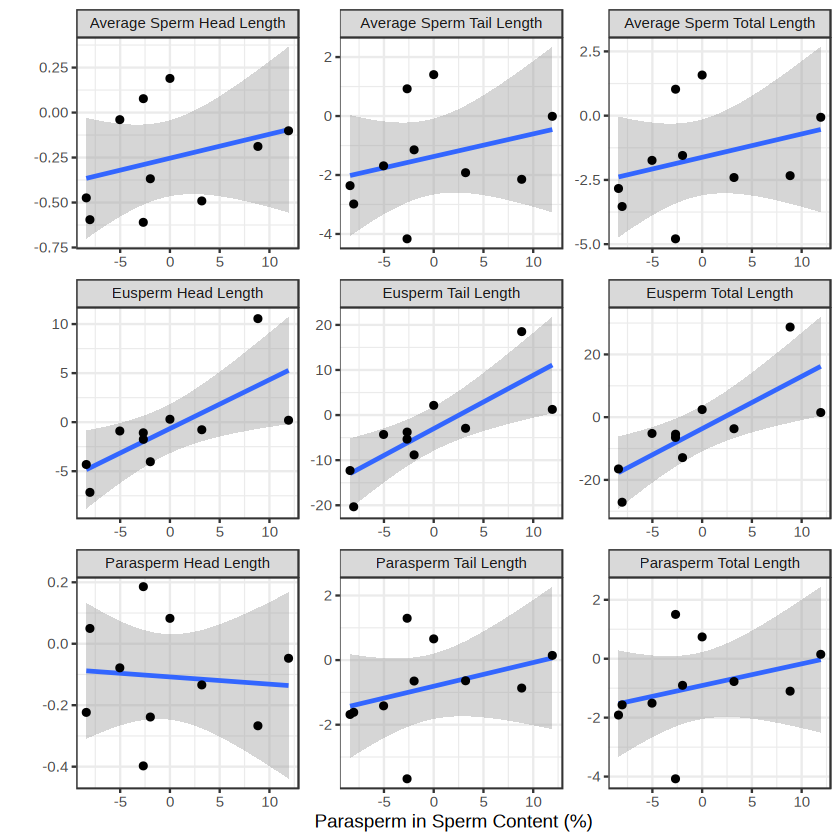

In [65]:
## plot sperm traits relative to sperm percent
pic_traits %>%
    rename("Eusperm Total Length" = eusperm_length,
           "Eusperm Head Length" = eusperm_head,
           "Eusperm Tail Length" = eusperm_tail,
           "Parasperm Total Length" = parasperm_length,
           "Parasperm Head Length" = parasperm_head,
           "Parasperm Tail Length" = parasperm_tail,
           "Average Sperm Head Length" = average_head,
           "Average Sperm Tail Length" = average_tail,
           "Average Sperm Total Length" = average_length,
           "Male Reproductive Tract\nMass (ug)" = mrt_mass) %>%
    pivot_longer(!percent_parasperm, names_to = "measure", values_to = "value") %>%
    filter(!grepl("Male", measure)) %>%
    ggplot(aes(x = percent_parasperm, y = value)) +
    geom_smooth(formula = y ~ x, method = "lm") +
    geom_point() +
    labs(x = "Parasperm in Sperm Content (%)", y = "") +
    theme_bw() +
    facet_wrap(~measure, scales = "free")

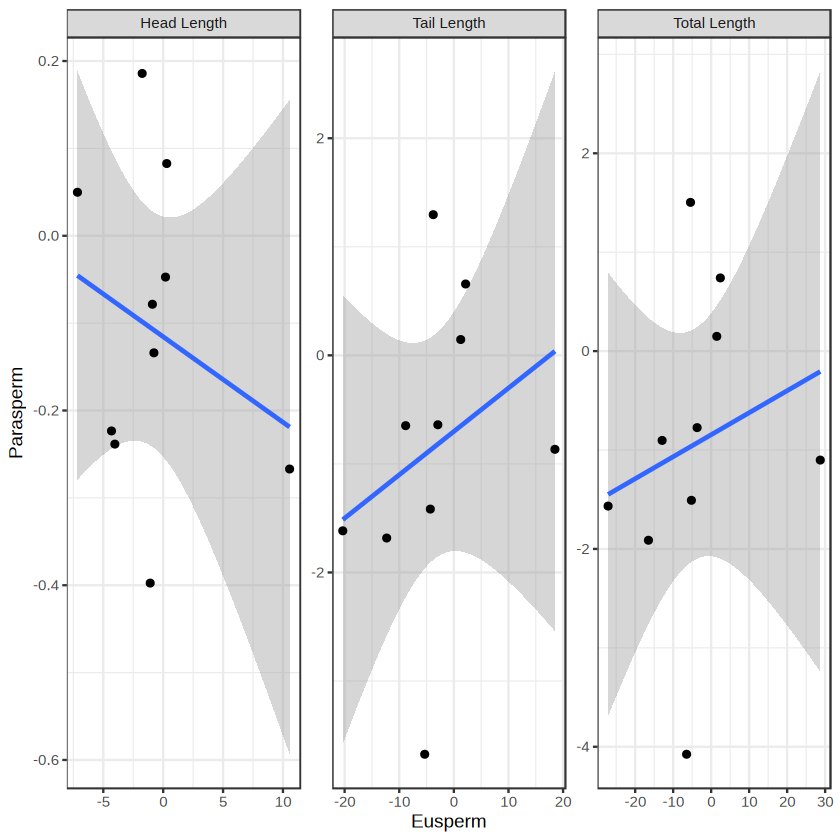

In [66]:
## plot traits between eusperm and parasperm
pic_traits %>%
    pivot_longer(!percent_parasperm, names_to = "measure", values_to = "value") %>%
    filter(!grepl("average", measure) & !grepl("mrt", measure)) %>%
    separate_wider_delim(measure, delim = "_", names = c("sperm_type", "measure")) %>%
    pivot_wider(names_from = sperm_type, values_from = value) %>%
    mutate(measure = case_when(measure == "length" ~ "Total Length",
                               measure == "head" ~ "Head Length",
                               measure == "tail" ~ "Tail Length")) %>%
    ggplot(aes(x = eusperm, y = parasperm)) +
        geom_smooth(formula = y ~ x, method = "lm") +
        labs(x = "Eusperm", y = "Parasperm") +
        geom_point() +
        theme_bw() +
        facet_wrap(~measure, scales = "free")

### Perform GO term analysis

In [67]:
# ## get list of GO terms
# go_terms <- unique(ontology$term)

# ## Look for GO terms enriched across clusters for each different group

# ## create empty dataframe to populate
# go_compared <- data.frame(go_term = character(),
#                           direction = character(),
#                           go_genes = double(),
#                           go_ratio = double(),
#                           go_pvalue = double())

# ## get list of genes in cluster category
# up_genes <- comparison_norm %>%
#     filter(comparison == "sex ratio_mutant" & direction == "hypo") %>%
#     pull("gene")
# down_genes <- comparison_norm %>%
#     filter(comparison == "sex ratio_mutant" & direction == "hyper") %>%
#     pull("gene")

# for (i in go_terms) {
    
#     ## format dataframe based on mutation type and associated go term
#     go_df <- ontology %>%
#         mutate(signif = case_when(gene %in% up_genes ~ "signif",
#                                   TRUE ~ "nontype"),
#                go = case_when(term == i ~ "go",
#                               TRUE ~ "nogo")) %>%
#         group_by(signif, go) %>%
#         count() %>%
#         pivot_wider(names_from = go, values_from = n) %>%
#         column_to_rownames("signif") %>%
#         mutate_all(replace_na, replace = 0)

#     ## get the number of genes with both mutation type and go term
#     signif_go <- go_df["signif", "go"]

#     ## only perform chi squared if there are more than 0 genes with go term
#     if (signif_go > 0) {        
        
#         ## perform chi-squared test
#         go_chi <- go_df %>%
#             as.matrix() %>%
#             chisq.test()
#         go_pvalue <- go_chi$p.value

#         ## populate dataframe with data
#         go_compared <- add_row(go_compared, go_term = i, 
#                                             direction = "up",
#                                             go_genes = signif_go, 
#                                             go_ratio = signif_go/length(up_genes), 
#                                             go_pvalue = go_pvalue)
        
#     } 

#     ## repeat for adaptive
#     go_df <- ontology %>%
#         mutate(signif = case_when(gene %in% down_genes ~ "signif",
#                                   TRUE ~ "nontype"),
#                go = case_when(term == i ~ "go",
#                               TRUE ~ "nogo")) %>%
#         group_by(signif, go) %>%
#         count() %>%
#         pivot_wider(names_from = go, values_from = n) %>%
#         column_to_rownames("signif") %>%
#         mutate_all(replace_na, replace = 0)
#     signif_go <- go_df["signif", "go"]

#     if (signif_go > 0) {        
#         go_chi <- go_df %>%
#             as.matrix() %>%
#             chisq.test()
#         go_pvalue <- go_chi$p.value
#         go_compared <- add_row(go_compared, go_term = i, 
#                                             direction = "down",
#                                             go_genes = signif_go, 
#                                             go_ratio = signif_go/length(down_genes), 
#                                             go_pvalue = go_pvalue)
#     } 

# }

# ## perform multiple testing correction
# go_compared$pvalue_corrected <- p.adjust(go_compared$go_pvalue, method = "BH")

In [68]:
# write.csv(go_compared, "intermediate/pseudoobscura_mutant_go.csv")

### Identify enrichment among differentially expressed genes

#### Identify testes specific enrichment

In [69]:
## chi squared for all differentially expressed genes
chisq_testes <- comparison_norm %>%
    mutate(testes = case_when(gene %in% testes_genes ~ "testes",
                              TRUE ~ "other")) %>%
    filter(comparison == "sex ratio_mutant") %>%
    group_by(testes, significance) %>%
    count() %>%
    pivot_wider(names_from = significance, values_from = n) %>%
    column_to_rownames("testes") %>%
    as.matrix() %>%
    chisq.test()
chisq_testes$p.value

[1] 2.085023e-05

In [70]:
## chi squared for different differentially expressed genes
chisq_up_testes <- comparison_norm %>%
    filter(comparison == "sex ratio_mutant") %>%
    mutate(testes = case_when(gene %in% testes_genes ~ "testes",
                              TRUE ~ "other"),
           increased = case_when(significance == "significant" & direction == "hypo" ~ "increased",
                                 TRUE ~ "other")) %>%
    group_by(testes, increased) %>%
    count() %>%
    pivot_wider(names_from = increased, values_from = n) %>%
    column_to_rownames("testes") %>%
    as.matrix() %>%
    chisq.test()
chisq_up_testes$p.value
chisq_down_testes <- comparison_norm %>%
    filter(comparison == "sex ratio_mutant") %>%
    mutate(testes = case_when(gene %in% testes_genes ~ "testes",
                              TRUE ~ "other"),
           increased = case_when(significance == "significant" & direction == "hyper" ~ "increased",
                                 TRUE ~ "other")) %>%
    group_by(testes, increased) %>%
    count() %>%
    pivot_wider(names_from = increased, values_from = n) %>%
    column_to_rownames("testes") %>%
    as.matrix() %>%
    chisq.test()
chisq_down_testes$p.value

[1] 2.428335e-109

[1] 7.451586e-176

In [71]:
## chi squared for all differentially expressed genes with reference, as control
chisq_testes <- comparison_norm %>%
    mutate(testes = case_when(gene %in% testes_genes ~ "testes",
                              TRUE ~ "other")) %>%
    filter(comparison == "reference_mutant") %>%
    group_by(testes, significance) %>%
    count() %>%
    pivot_wider(names_from = significance, values_from = n) %>%
    column_to_rownames("testes") %>%
    as.matrix() %>%
    chisq.test()
chisq_testes$p.value
chisq_testes <- comparison_norm %>%
    mutate(testes = case_when(gene %in% testes_genes ~ "testes",
                              TRUE ~ "other")) %>%
    filter(comparison == "sex ratio_reference") %>%
    group_by(testes, significance) %>%
    count() %>%
    pivot_wider(names_from = significance, values_from = n) %>%
    column_to_rownames("testes") %>%
    as.matrix() %>%
    chisq.test()
chisq_testes$p.value

[1] 8.248402e-07

[1] 0.3035263

#### Identify chromosome specific enrichment

In [72]:
## create GRanges object of all of the genes
genes <- genes(dpse_ranges)

## get list of differentially expresed genes
diff_genes <- comparison_norm %>%
    filter(significance == "significant") %>%
    pull("gene")

## get list of genes in each category 
upregulated_genes <- comparison_norm %>%
    filter(comparison == "sex ratio_mutant" & direction == "hypo" & significance == "significant") %>%
    pull("gene")
downregulated_genes <- comparison_norm %>%
    filter(comparison == "sex ratio_mutant" & direction == "hyper" & significance == "significant") %>%
    pull("gene")

## clean up fasta names
fasta_names <- names(dpse_fasta) %>%
    as.data.frame() %>%
    rename(original = 1) %>%
    separate_wider_delim(original, delim = ",", names = c("specifics", "scaffold", "sequencing"), cols_remove = FALSE) %>%
    select(-c(scaffold, sequencing)) %>%
    separate_wider_delim(specifics, delim = " ", names = c("name", "genus", "species", "trash1", "strain", "trash2", "chromosome"), 
                         too_many = "merge", too_few = "align_start") %>%
    select(-c(genus, species, trash1, strain)) %>%
    mutate(chromosome = case_when(trash2 == "chromosome" ~ chromosome,
                                  trash2 == "mitochondrion" ~ "mitochondrion",
                                  TRUE ~ "scaffold")) %>%
    select(original, name, chromosome)

## annotate all of the genes with location and expression
gene_characteristics <- genes %>%
    as_tibble() %>%
    select(seqnames, gene_id) %>%
    mutate(diff = case_when(gene_id %in% diff_genes ~ "diff",
                            TRUE ~ "nondiff"),
           dir = case_when(gene_id %in% upregulated_genes ~ "up",
                           gene_id %in% downregulated_genes ~ "down",
                           TRUE ~ "nondiff")) %>%
    rename(name = seqnames) %>%
    left_join(fasta_names, by = "name") %>%
    select(-c(original, name)) %>%
    mutate(x_chr = case_when(chromosome == "X" ~ "x_chr",
                            TRUE ~ "other_chr"))

## find the percentage of genes that are differentially expressed across chromosome
total_genes <- nrow(gene_characteristics)
signif_genes <- gene_characteristics %>%
    filter(diff == "diff") %>%
    nrow()

(signif_genes/total_genes)*100

[1] 42.18009

In [73]:
write_csv(gene_characteristics, "intermediate/gene_chromosome.csv")

In [74]:
## get the percentage of genes on autosomes that are differentially expressed
nonx_genes <- gene_characteristics %>%
    filter(chromosome != "X") %>%
    nrow()
nonx_signif_genes <- gene_characteristics %>%
    filter(chromosome != "X" & diff == "diff") %>%
    nrow()
nonx_down_genes <- gene_characteristics %>%
    filter(chromosome != "X" & dir == "down") %>%
    nrow()

(nonx_signif_genes/nonx_genes)*100
(nonx_down_genes/nonx_genes)*100

[1] 43.51938

[1] 16.25255

In [75]:
## get the percentage of genes on the X chromosome that are differentially expressed
x_genes <- gene_characteristics %>%
    filter(chromosome == "X") %>%
    nrow()
x_signif_genes <- gene_characteristics %>%
    filter(chromosome == "X" & diff == "diff") %>%
    nrow()
x_down_genes <- gene_characteristics %>%
    filter(chromosome == "X" & dir == "down") %>%
    nrow()

(x_signif_genes/x_genes)*100
(x_down_genes/x_genes)*100

[1] 39.80965

[1] 10.71546

In [76]:
## calculate enrichment of differentially expressed genes on X chromosome
x_diff_chi <- gene_characteristics %>%
    select(gene_id, diff, x_chr) %>%
    group_by(diff, x_chr) %>%
    count() %>%
    pivot_wider(names_from = diff, values_from = n) %>%
    column_to_rownames("x_chr") %>%
    as.matrix() %>%
    chisq.test()
x_diff_chi$p.value

[1] 2.992799e-06

In [77]:
## calculate enrichment of downregulated genes on X chromosome
up_diff_chi <- gene_characteristics %>%
    select(gene_id, dir, x_chr) %>%
    group_by(dir, x_chr) %>%
    filter(dir != "up") %>%
    count() %>%
    pivot_wider(names_from = dir, values_from = n) %>%
    column_to_rownames("x_chr") %>%
    as.matrix() %>%
    chisq.test()
up_diff_chi$p.value

[1] 7.862772e-22

In [78]:
## calculate enrichment of upregulated genes on X chromosome
down_diff_chi <- gene_characteristics %>%
    select(gene_id, dir, x_chr) %>%
    group_by(dir, x_chr) %>%
    filter(dir != "down") %>%
    count() %>%
    pivot_wider(names_from = dir, values_from = n) %>%
    column_to_rownames("x_chr") %>%
    as.matrix() %>%
    chisq.test()
down_diff_chi$p.value

[1] 0.5474331

#### Identify intersection of testes specificity and X chromosome position

In [79]:
## find if enriched in all differentially expressed genes
all_xtest <- gene_characteristics %>%
    mutate(xtest = case_when(x_chr == x_chr & gene_id %in% testes_genes ~ "yes",
                             TRUE ~ "no")) %>%
    group_by(diff,xtest) %>%
    count() %>%
    pivot_wider(names_from = diff, values_from = n) %>%
    column_to_rownames("xtest") %>%
    as.matrix() %>%
    chisq.test()
all_xtest$p.value

[1] 2.555237e-133

In [80]:
## find if enriched in down genes
up_xtest <- gene_characteristics %>%
    filter(dir != "up") %>%
    mutate(xtest = case_when(x_chr == x_chr & gene_id %in% testes_genes ~ "yes",
                             TRUE ~ "no")) %>%
    group_by(dir, xtest) %>%
    count() %>%
    pivot_wider(names_from = dir, values_from = n) %>%
    column_to_rownames("xtest") %>%
    as.matrix() %>%
    chisq.test()
up_xtest$p.value

down_xtest <- gene_characteristics %>%
    filter(dir != "down") %>%
    mutate(xtest = case_when(x_chr == x_chr & gene_id %in% testes_genes ~ "yes",
                             TRUE ~ "no")) %>%
    group_by(dir ,xtest) %>%
    count() %>%
    pivot_wider(names_from = dir, values_from = n) %>%
    column_to_rownames("xtest") %>%
    as.matrix() %>%
    chisq.test()
down_xtest$p.value

[1] 3.097983e-311

[1] 1.072472e-08

## Associate Genes with parasperm content across obscura Group

### Set up Data

In [81]:
## load in results from CAGEE
credible_df <- read_csv("../workflow/tools/CAGEE/credible_genes.csv")

Rows: 844 Columns: 5
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (4): transcript_id, x_12, x_14, x_15
num (1): signif

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [82]:
## get genes with credible changes at nodes with increases in gene expression (without conflicting if present in multiple)
credible_genes <- credible_df %>%
    pull("transcript_id")
length(unique(credible_genes))

[1] 844

In [83]:
## load in gene expression data
raw_reads <- read_tsv("../workflow/tools/obscura_group_reads.tsv") %>%
    janitor::clean_names() %>%
    as.data.frame() %>%
    select(-desc)

## load in tree
tree <- ape::read.tree("../workflow/tools/select_obscura_tree.nwk")

Rows: 16880 Columns: 10
── Column specification ────────────────────────────────────────────────────────
Delimiter: "\t"
chr (2): DESC, Gene_ID
dbl (8): Drosophila_affinis, Drosophila_azteca, Drosophila_bifasciata, Droso...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [84]:
## load in parasperm information
parasperm <- read_csv("../workflow/tools/parasperm_proportion.csv", skip = 1) %>%
    janitor::clean_names() %>%
    mutate(species = str_replace(species, "D. ", "Drosophila_")) %>%
    rename(parasperm = 2) %>%
    select(species, parasperm)

New names:
• `` -> `...5`
Rows: 10 Columns: 5
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (4): species, Category, Remating in days (from Holman et al 2007 Evoluti...
dbl (1): % Parasperm

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


### Identify GO terms that are enriched among branch associated genes

In [85]:
# ## Look for GO terms enriched across clusters for each different group

# ## create empty dataframe to populate
# go_compared <- data.frame(go_term = character(),
#                           go_genes = double(),
#                           go_ratio = double(),
#                           go_pvalue = double())

# for (i in go_terms) {
    
#     ## format dataframe based on mutation type and associated go term
#     go_df <- ontology %>%
#         mutate(signif = case_when(gene %in% credible_genes ~ "signif",
#                                   TRUE ~ "nontype"),
#                go = case_when(term == i ~ "go",
#                               TRUE ~ "nogo")) %>%
#         group_by(signif, go) %>%
#         count() %>%
#         pivot_wider(names_from = go, values_from = n) %>%
#         column_to_rownames("signif") %>%
#         mutate_all(replace_na, replace = 0)

#     ## get the number of genes with both mutation type and go term
#     signif_go <- go_df["signif", "go"]

#     ## only perform chi squared if there are more than 0 genes with go term
#     if (signif_go > 0) {        
        
#         ## perform chi-squared test
#         go_chi <- go_df %>%
#             as.matrix() %>%
#             chisq.test()
#         go_pvalue <- go_chi$p.value

#         ## populate dataframe with data
#         go_compared <- add_row(go_compared, go_term = i, 
#                                             go_genes = signif_go, 
#                                             go_ratio = signif_go/length(credible_genes), 
#                                             go_pvalue = go_pvalue)
        
#     } 
# }

# ## perform multiple testing correction
# go_compared$pvalue_corrected <- p.adjust(go_compared$go_pvalue, method = "BH")

# write.csv(go_compared, "intermediate/credible_go.csv")

### Determine if there is enrichment for branch associated genes on X or in testes specificity

## Compare parasperm associated genes with mutant information

### Create data frame of most variable genes

In [88]:
## perform a PCA on the reads
pca <- raw_reads %>%
    column_to_rownames("gene_id") %>%
    as.matrix() %>%
    t() %>%
    prcomp()
summary(pca)

## determines genes that contribute to variation
pca_loading <- pca$rotation %>%
    as.data.frame() %>%
    select(PC1, PC2, PC3) %>%
    rownames_to_column("gene") %>%
    pivot_longer(!gene, names_to = "pc", values_to = "loading") %>%
    group_by(pc) %>% 
    arrange(desc(abs(loading)))

## get top 20% of genes that explain variance
var_genes <- pca_loading %>%
    slice(1:(length(unique(pca_loading$gene))/5)) %>%
    pull("gene") %>%
    unique()

## reformat reads so each gene is a row and each species is a column
reads <- raw_reads %>%
    filter(gene_id %in% var_genes) %>% ## filter for only the most variable genes
    mutate_at(vars(-gene_id), as.double) %>%
    column_to_rownames("gene_id") %>%
    t() %>%
    as.data.frame() %>%
    rownames_to_column("species") %>%
    mutate(species = str_replace(species, "drosophila", "Drosophila")) %>%
    column_to_rownames("species")

## get list of species
species <- rownames(reads)

Importance of components:
                             PC1       PC2       PC3       PC4       PC5
Standard deviation     4.939e+05 4.470e+05 4.065e+05 2.969e+05 2.914e+05
Proportion of Variance 2.814e-01 2.304e-01 1.906e-01 1.017e-01 9.792e-02
Cumulative Proportion  2.814e-01 5.119e-01 7.025e-01 8.042e-01 9.021e-01
                             PC6       PC7       PC8
Standard deviation     2.456e+05 1.567e+05 5.255e-10
Proportion of Variance 6.958e-02 2.833e-02 0.000e+00
Cumulative Proportion  9.717e-01 1.000e+00 1.000e+00

### Identify enrichment of parasperm associated genes among differentially expressed genes

In [91]:
## combine differential expression and parasperm data
annotated_logfc <- colnames(reads) %>%
    as.data.frame() %>%
    rename(gene = 1) %>%
    left_join(comparison_norm, by = "gene") %>%
    mutate(logfc = -(logfc),
           credible = case_when(gene %in% credible_genes ~ "credible",
                                TRUE ~ "non-credible"),
           significance = case_when(is.na(significance) ~ "not significant",
                                    TRUE ~ significance),
           color = case_when(is.na(color) ~ "not significant",
                             TRUE ~ color),
           direction = case_when(significance == "significant" & logfc < 0 ~ "hypo",
                                 significance == "significant" & logfc > 0 ~ "hyper",
                                 TRUE ~ "not significant"),
           testes_specificity = case_when(gene %in% testes_genes ~ "testes",
                                          TRUE ~ "other"),
           x = case_when(gene %in% x_genes ~ "x",
                         TRUE ~ "other")) %>%
    unique()

## compare number of significant genes to those with credible and adaptive
credible_logfc <- annotated_logfc %>%
    group_by(credible, significance) %>%
    count() %>%
    pivot_wider(names_from = significance, values_from = n) %>%
    column_to_rownames("credible") %>%
    mutate_all(replace_na, replace = 0) %>%
    as.matrix()

## perform chi squared test
chisq.test(credible_logfc)$p.value

[1] 4.323679e-14

In [92]:
write_csv(annotated_logfc, "intermediate/full_annotated_logfc.csv")

In [93]:
## now look at credible, separating increase and decrease
credible_up <- annotated_logfc %>%
    filter(direction != "hyper") %>%
    group_by(credible, direction) %>%
    count() %>%
    pivot_wider(names_from = direction, values_from = n) %>%
    column_to_rownames("credible") %>%
    mutate_all(replace_na, replace = 0) %>%
    as.matrix() %>%
    chisq.test()
credible_up$p.value

credible_down <- annotated_logfc %>%
    filter(direction != "hypo") %>%
    group_by(credible, direction) %>%
    count() %>%
    pivot_wider(names_from = direction, values_from = n) %>%
    column_to_rownames("credible") %>%
    mutate_all(replace_na, replace = 0) %>%
    as.matrix() %>%
    chisq.test()
credible_down$p.value

[1] 1.269553e-62

[1] 7.68568e-12

### Identify GO terms associated with branch associated genes that are upregulated in the mutant

In [94]:
# ## look for enriched GO terms in for credible, up-regulated genes

# ## get list of credible, up-regulated genes
# upcred_genes <- annotated_logfc %>%
#     filter(credible == "credible" & direction == "hypo") %>%
#     pull("gene")

# ## create empty dataframe to populate
# go_compared <- data.frame(go_term = character(),
#                           go_genes = double(),
#                           go_ratio = double(),
#                           go_pvalue = double())

# for (i in go_terms) {    
    
#     ## format dataframe based on associated go term
#     go_df <- ontology %>%
#         mutate(signif = case_when(gene %in% upcred_genes ~ "signif",
#                                     TRUE ~ "nontype"),
#                go = case_when(term == i ~ "go",
#                               TRUE ~ "nogo")) %>%
#         group_by(signif, go) %>%
#         count() %>%
#         pivot_wider(names_from = go, values_from = n) %>%
#         column_to_rownames("signif") %>%
#         mutate_all(replace_na, replace = 0)

#     ## get the number of genes with go term
#     signif_go <- go_df["signif", "go"]

#     ## only perform chi squared if there are more than 0 genes with go term
#     if (signif_go > 0) {        
        
#         ## perform chi-squared test
#         go_chi <- go_df %>%
#             as.matrix() %>%
#             chisq.test()
#         go_pvalue <- go_chi$p.value

#         ## populate dataframe with data
#         go_compared <- add_row(go_compared, go_term = i, 
#                                             go_genes = signif_go, 
#                                             go_ratio = signif_go/length(upcred_genes), 
#                                             go_pvalue = go_pvalue)
        
#     }    
# }

# ## perform multiple testing correction
# go_compared$pvalue_corrected <- p.adjust(go_compared$go_pvalue, method = "BH")

# write.csv(go_compared, "intermediate/credible_up_go.csv")

## Investigate mutant genes in single cell data set

## Investigate specific genes that would be of interest based on previous literature

### Set up Data

In [95]:
## load in orthologs between D. melanogaster and D. pseudoobscura
mel_ortho <- read_delim("../workflow/trinotate/drosoma_pse_mel.txt", col_names = FALSE)
names(mel_ortho) <- c("dpse", "dmel", "paralog", "score")

Rows: 13772 Columns: 4
── Column specification ────────────────────────────────────────────────────────
Delimiter: "\t"
chr (3): X1, X2, X3
dbl (1): X4

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


### Search data for specific genes

In [96]:
## add shortened symbol names to SFP list
sfp$dmel <- c("alphaTub84D", "Acp36DE", "CG17097", "CG31872", "regucalcin",
              "Tsf1", "scpr-C", "Acp26Aa", "Ebp", "CG17242", "CtsK2", "CG17472",
              "NT5E-2", "CG5162", "CG34051", "mfas", "Nlaz", "lectin-30A", 
              "Hsc70-3", "Idgf4", "Pde1c", "Spn38F", "CG18284", "CG11037", "EbpII",
              "Spn28F", "Acp53C14a", "Sfp26Ad", "Treh", "Idgf3", "CG15117", 
              "CG14034", "Sfp24Bb", "Sfp87B", "Spn77Bb", "lectin-29Ca", "Gp93", 
              "CG2852", "Est-6", "Acp53C14b", "CG31659", "CG6357", "CG18258", 
              "CG42564", "Obp51a", "Acp53Ea", "Calr", "CG6071", "CG11598", "OstDelta",
              "Swim", "CG34130", "Spn77Bc", "Spn75F", "CG34102", "lectin-46Cb", 
              "antr", "lectin-46Ca", "Spn28B", "Sfp38D", "CG31198", "CG17549", 
              "CG31680", "CG11608", "Grp170", "CG34033", "CG15394", "CG31883")

## identify D. pseudoobscura paralogs
test <- sfp %>%
    inner_join(mel_ortho, by = "dmel") %>%
    select(Symbol, dpse) %>%
    rename(sfp = Symbol, gene = dpse)

## determine if SFPs appear in our data set as differentially expressed are associated with parasperm
annotated_logfc %>%
    inner_join(test, by = "gene") %>%
    filter(comparison == "sex ratio_mutant")

gene,...1,comparison,logfc,pvalue,significance,direction,color,credible,testes_specificity,x,sfp
<chr>,<dbl>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
LOC6898901,11591,sex ratio_mutant,0.52884180,2.621107e-06,significant,hyper,marginally differentially expressed,non-credible,other,other,Oligosaccharide transferase Delta subunit
LOC6898992,11987,sex ratio_mutant,0.59889541,1.037308e-04,significant,hyper,marginally differentially expressed,non-credible,other,other,Trehalase
LOC4805293,11411,sex ratio_mutant,-0.33876997,1.200447e-03,significant,hypo,marginally differentially expressed,non-credible,other,other,CG2852
LOC4805742,12452,sex ratio_mutant,0.59137840,2.660553e-07,significant,hyper,marginally differentially expressed,non-credible,other,other,CG15117
LOC4817494,17783,sex ratio_mutant,0.03738714,9.998863e-01,not significant,not significant,not significant,non-credible,other,other,Imaginal disc growth factor 3
LOC4817554,17918,sex ratio_mutant,-0.34200737,6.013668e-03,significant,hypo,marginally differentially expressed,non-credible,other,other,Phosphodiesterase 1c
LOC6901019,18869,sex ratio_mutant,1.62654994,4.745812e-05,significant,hyper,marginally differentially expressed,non-credible,other,other,Transferrin 1
LOC4814222,19001,sex ratio_mutant,1.75668576,2.190587e-04,significant,hyper,marginally differentially expressed,non-credible,other,other,Imaginal disc growth factor 4
LOC4815330,21830,sex ratio_mutant,-0.04554030,9.991441e-01,not significant,not significant,not significant,non-credible,other,other,regucalcin


In [97]:
## determine if any sperm proteins are in the data set
annotated_logfc %>%
    rename(symbol = gene) %>%
    inner_join(sperm_dpse, by = "symbol") %>%
    filter(comparison == "sex ratio_mutant")

symbol,...1,comparison,logfc,pvalue,significance,direction,color,credible,testes_specificity,x,sperm_protein
<chr>,<dbl>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
LOC4817494,17783,sex ratio_mutant,0.03738714,9.998863e-01,not significant,not significant,not significant,non-credible,other,other,Idgf3
LOC4817554,17918,sex ratio_mutant,-0.34200737,6.013668e-03,significant,hypo,marginally differentially expressed,non-credible,other,other,Phosphodiesterase 1c
LOC6901019,18869,sex ratio_mutant,1.62654994,4.745812e-05,significant,hyper,marginally differentially expressed,non-credible,other,other,Transferrin 1
LOC4814222,19001,sex ratio_mutant,1.75668576,2.190587e-04,significant,hyper,marginally differentially expressed,non-credible,other,other,Imaginal disc growth factor 4
LOC26532861,6593,sex ratio_mutant,-0.50714680,7.927122e-05,significant,hypo,marginally differentially expressed,non-credible,testes,other,SCP-containing protein C
LOC4803148,6605,sex ratio_mutant,1.01286730,8.833909e-09,significant,hyper,marginally differentially expressed,non-credible,testes,other,SCP-containing protein C


In [98]:
## nebenkern formation
## fzo (fuzzy onion) - not found (first gene related to mitochondria, cannot aggregate)
## Larp - not found (partitions mitochondria into nebenkern)
## Pink1 (LOC4815974) - not differential (maintains separation)
## Parkin - not found (maintains separation) -> tried park (uniprot), not differential
test <- mel_ortho %>%
    filter(dmel == "park") %>%
    pull("dpse")
annotated_logfc %>%
    filter(gene %in% test)

gene,...1,comparison,logfc,pvalue,significance,direction,color,credible,testes_specificity,x
<chr>,<dbl>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
LOC4812935,26104,sex ratio_reference,0.1605059,9.861460e-01,not significant,not significant,not significant,non-credible,other,other
LOC4812935,26105,sex ratio_mutant,-0.2605455,2.726715e-01,not significant,not significant,not significant,non-credible,other,other
LOC4812935,26106,reference_mutant,-0.4317933,2.930068e-05,significant,hypo,marginally differentially expressed,non-credible,other,other


In [99]:
## nebenkern unfurling
## Milton - not found (anchors nebernkern to nuclei and allows sliding of microtubules) -> tried milt (uniprot), not significant
## Lis-1 (LOC4803869) - not differential (anchors nebenkern to nuclei)
## Miro (LOC4801756) - not differential (allows sliding of cytosolic microtubules)
## Nebbish - not found (elongation is truncated) -> tried neb (uniprot), not significant
## Khc73 - not found (elongation is truncated) -> tried Khc-73 (uniprot), significant
## fascetto - not found (elongation is truncated)  -> tried feo (uniprot), significant
## nmd (LOC117183914) - not differential (decreased number of mitochondria)
## cnn (LOC4804379) - not differential (required for assembly of flagellar axoneme)
## Grip members - 3/7 differentially expressed (localize to basal body for microtubule formation)
test <- mel_ortho %>%
    filter(dmel == "feo") %>%
    pull("dpse")
annotated_logfc %>%
    filter(gene %in% test)

gene,...1,comparison,logfc,pvalue,significance,direction,color,credible,testes_specificity,x
<chr>,<dbl>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>


In [100]:
## mitochondrial energetics
## Mic26-27 - not found (part of cristae organizing system)
## QIL1 (LOC4812916) - not differential (part of cristae organizing system)
## Mitofilin (LOC6896986) - not differential (part of cristae organizing system)
## Chchd3 (LOC4800334) - not differential (part of cristae organizing system)
## knon (LOC4803786) - not differential (electron transportation)
## knon (LOC4803786) - not differential (electron transportation)
## blw (LOC4803853) - differential (electron transportation)
test <- mel_ortho %>%
    filter(dmel == "Mic26-27") %>%
    pull("dpse")
annotated_logfc %>%
    filter(gene %in% test)

gene,...1,comparison,logfc,pvalue,significance,direction,color,credible,testes_specificity,x
<chr>,<dbl>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>


In [101]:
## list of genes with differential expression
mito_genes <- c("Khc-73", "feo", "blw")
mel_ortho %>%
    filter(dmel %in% mito_genes | grepl("Grip", dmel)) %>%
    select(dpse, dmel) %>%
    rename(gene = dpse) %>%
    left_join(annotated_logfc, by = "gene") %>%
    select(-c(pvalue, direction, color))

gene,dmel,...1,comparison,logfc,significance,credible,testes_specificity,x
<chr>,<chr>,<dbl>,<chr>,<dbl>,<chr>,<chr>,<chr>,<chr>
LOC4803853,blw,8242,sex ratio_reference,-0.03041809,not significant,non-credible,other,other
LOC4803853,blw,8243,sex ratio_mutant,0.40758905,significant,non-credible,other,other
LOC4803853,blw,8244,reference_mutant,0.42718849,significant,non-credible,other,other
LOC4804863,Khc-73,10480,sex ratio_reference,0.38040852,significant,non-credible,other,other
LOC4804863,Khc-73,10481,sex ratio_mutant,0.47056894,significant,non-credible,other,other
LOC4804863,Khc-73,10482,reference_mutant,0.07944228,not significant,non-credible,other,other
LOC6899804,Grip75,NA,NA,NA,NA,NA,NA,NA
LOC4817648,Grip71,NA,NA,NA,NA,NA,NA,NA
LOC6902241,feo,NA,NA,NA,NA,NA,NA,NA


In [102]:
## acrosome genes
## Four way stop (fws) - not differential (golgi and endosomal trafficking regulators)
## Giotto (Gio) - not found (golgi and endosomal trafficking regulators)
## Rab11 - not differential (golgi and endosomal trafficking regulators)
## Nuclear fallout (nuf) - not differential (Rab11 effector Nuclear fallout)
## Brunelleschi (brun) - differential (golgi and endosomal trafficking regulators)
## Lectin Wheat Germ Agglutinin (WGA) - not found (secretory trafficking)
## Sneaky (snky) - differential (sperm plasma membrane breakdown during fertilization)
## Misfire (mfr) - differential (sperm plasma membrane breakdown)
test <- mel_ortho %>%
    filter(dmel == "mfr") %>%
    pull("dpse")
annotated_logfc %>%
    filter(gene %in% test)

gene,...1,comparison,logfc,pvalue,significance,direction,color,credible,testes_specificity,x
<chr>,<dbl>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>


In [103]:
## golgi apparatus genes
## Golgins lava lamp (Lva) - differential
## GCC88 - not differential
## GM130 - not differential
## Golgi alpha-mannosidase II (GMII) - not found; (alpha-Man-IIa) - differential
## Golgi phosphoprotein-3 (GOLPHh3) - not found; (sau) - not differential
## Coatomer (COP I) - not found; (gammaCOP) - not significant
## Gga - not differential (clathrin adaptors)
## AP-1 - not found (clathrin adaptors)
test <- mel_ortho %>%
    filter(dmel == "AP-1") %>%
    pull("dpse")
annotated_logfc %>%
    filter(gene %in% test)

gene,...1,comparison,logfc,pvalue,significance,direction,color,credible,testes_specificity,x
<chr>,<dbl>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>


In [104]:
## search for aquaporins
test <- mel_ortho %>%
    filter(grepl("AQP", dmel)) %>%
    pull("dpse")
annotated_logfc %>%
    filter(gene %in% test)

gene,...1,comparison,logfc,pvalue,significance,direction,color,credible,testes_specificity,x
<chr>,<dbl>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>


In [105]:
## Odarant binding genes (Obp) - (odarant binding genes essential to male fertility)
test <- mel_ortho %>%
    filter(dmel == "lush") %>%
    pull("dpse")
annotated_logfc %>%
    filter(gene %in% test)
test <- mel_ortho %>%
    filter(grepl("Obp", dmel)) %>%
    rename(gene = dpse)
annotated_logfc %>%
    right_join(test, by = "gene")

gene,...1,comparison,logfc,pvalue,significance,direction,color,credible,testes_specificity,x
<chr>,<dbl>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>


gene,...1,comparison,logfc,pvalue,significance,direction,color,credible,testes_specificity,x,dmel,paralog,score
<chr>,<dbl>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>
LOC4804338,9340,sex ratio_reference,0.08624418,9.989181e-01,not significant,not significant,not significant,non-credible,other,other,Obp44a,1:1,18154
LOC4804338,9341,sex ratio_mutant,-0.79341126,5.597574e-09,significant,hypo,marginally differentially expressed,non-credible,other,other,Obp44a,1:1,18154
LOC4804338,9342,reference_mutant,-0.89034676,3.165819e-08,significant,hypo,marginally differentially expressed,non-credible,other,other,Obp44a,1:1,18154
LOC6898273,8299,sex ratio_reference,-0.29431668,5.109756e-02,not significant,not significant,not significant,credible,testes,other,Obp50b,1:1,6996
LOC6898273,8300,sex ratio_mutant,0.06703936,9.977918e-01,not significant,not significant,not significant,credible,testes,other,Obp50b,1:1,6996
LOC6898273,8301,reference_mutant,0.35057339,8.052154e-04,significant,hyper,marginally differentially expressed,credible,testes,other,Obp50b,1:1,6996
LOC4800495,565,sex ratio_reference,0.08364647,9.991988e-01,not significant,not significant,not significant,non-credible,other,other,Obp99a,1:1,18152
LOC4800495,566,sex ratio_mutant,-0.26816585,2.086075e-01,not significant,not significant,not significant,non-credible,other,other,Obp99a,1:1,18152
LOC4800495,567,reference_mutant,-0.36259679,2.377359e-03,significant,hypo,marginally differentially expressed,non-credible,other,other,Obp99a,1:1,18152
